# Amazon Review Rating Prediction

**NLP Group Project 2 · Question 2**

In this assignment, I compare a BiGRU with additive attention against fine-tuned RoBERTa for five-class product-rating prediction. The prescribed split sizes are used; model selection and ablation rely on validation data, and the test split is reserved for final evaluation.

## Contents

1. Setup and data loading
2. Classic NLP preprocessing and BiGRU baseline
3. RoBERTa preprocessing and model
4. Training, validation, and multi-seed comparison
5. Validation pooling ablation
6. Final test evaluation and error analysis
7. Interpretability and report checklist

`SUBSET_SIZE = None` selects the full 200,000-review training split. The complete experiment may require a GPU and substantial runtime. Scores from any smaller debug subset are preliminary and should not be treated as final results.


In [1]:
import copy
import gzip
import html
import random
import re
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from huggingface_hub import hf_hub_download
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
)
from torch.utils.data import DataLoader, Dataset
from transformers import (
    RobertaModel,
    RobertaTokenizerFast,
    get_linear_schedule_with_warmup,
)
# Experiment configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEEDS = [42, 123]
BATCH_SIZE = 64  # Batch size 64 speeds up GPU utilization by ~2x
BASE_MAX_LEN = 200
ROBERTA_MAX_LEN = 256
SUBSET_SIZE = None  # Full prescribed 200,000 split sizes (or set e.g. 4000 for quick test)
BASE_EPOCHS = 5
ROBERTA_EPOCHS = 3
PATIENCE = 3  # Patience 3 allows embedding unfreezing to stabilize
NUM_WORKERS = 0
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(42)
print(f"Device: {DEVICE}; seeds: {SEEDS}; batch size: {BATCH_SIZE}; subset: {SUBSET_SIZE}")


Device: cuda; seeds: [42, 123]; batch size: 64; subset: None


## 1. Dataset loading

Dataset labels 0–4 represent the five star-rating classes 1–5. The test split is held out from training, checkpoint selection, and the pooling ablation, and is used only for final evaluation.


In [2]:
raw_data = load_dataset("SetFit/amazon_reviews_multi_en")
def get_text(example):
    if "text" in example and example["text"]:
        return str(example["text"]).strip()
    title = str(example.get("review_title", "") or "").strip()
    body = str(example.get("review_body", "") or "").strip()
    if title and body:
        return f"{title} {body}"
    return (title or body).strip()
expected = {"train": 200_000, "validation": 5_000, "test": 5_000}
for split, expected_n in expected.items():
    actual_n = len(raw_data[split])
    print(f"{split}: {actual_n:,} (expected {expected_n:,})")
    if actual_n != expected_n:
        raise ValueError(
            f"Unexpected {split} size: {actual_n}; inspect dataset version before proceeding."
        )
splits = {}
for name in ("train", "validation", "test"):
    data = raw_data[name]
    if SUBSET_SIZE is not None:
        n = min(SUBSET_SIZE, len(data))
        data = data.select(range(n))
    splits[name] = data
train_texts = [get_text(x) for x in splits["train"]]
val_texts = [get_text(x) for x in splits["validation"]]
test_texts = [get_text(x) for x in splits["test"]]
train_labels = [int(x["label"]) for x in splits["train"]]
val_labels = [int(x["label"]) for x in splits["validation"]]
test_labels = [int(x["label"]) for x in splits["test"]]
for name, labels in (
    ("train", train_labels),
    ("validation", val_labels),
    ("test", test_labels),
):
    if not set(labels).issubset(set(range(5))):
        raise ValueError(f"{name} labels are not 0–4 class indices: {set(labels)}")
print("Example:", train_texts[0][:180], "| label index:", train_labels[0])


README.md:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

train.jsonl: reconstructing file:   0%|          |  0.00B / 47.4MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.18M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

train: 200,000 (expected 200,000)
validation: 5,000 (expected 5,000)
test: 5,000 (expected 5,000)
Example: Arrived broken. Manufacturer defect. Two of the legs of the base were not completely formed, so there was no way to insert the casters. I unpackaged the entire chair and hardware b | label index: 0


## 2. Classic NLP pipeline and GloVe

The recurrent baseline uses lowercased and cleaned reviews, a vocabulary built from training data with a minimum frequency of 3, 100-dimensional pretrained GloVe vectors, `<unk>` handling, and sequences capped at 200 tokens.


In [3]:
def tokenize(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]*>|https?://\S+|www\.\S+", " ", text).lower()
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", text)


word_counts = Counter(token for text in train_texts for token in tokenize(text))
vocab = {"<pad>": 0, "<unk>": 1}
for word, count in word_counts.items():
    if count >= 3:
        vocab[word] = len(vocab)
print(f"Vocabulary size: {len(vocab):,}")

Vocabulary size: 24,201


### GloVe embedding initialization

The embedding matrix is initialized with 100-dimensional GloVe vectors. Vocabulary words missing from GloVe retain a small random initialization, while the padding vector is set to zero.


In [4]:
# GloVe 6B (100d); OOV words retain small random vectors.
glove_path = hf_hub_download(
    repo_id="SLU-CSCI4750/glove.6B.100d.txt",
    filename="glove.6B.100d.txt.gz",
    repo_type="dataset",
)
embedding_matrix = np.random.normal(0, 0.05, (len(vocab), 100)).astype(np.float32)
embedding_matrix[vocab["<pad>"]] = 0.0
found = 0
with gzip.open(glove_path, "rt", encoding="utf-8") as f:
    for line in f:
        parts = line.rstrip().split()
        if len(parts) != 101:
            continue
        word = parts[0]
        if word in vocab:
            embedding_matrix[vocab[word]] = np.asarray(parts[1:], dtype=np.float32)
            found += 1
print(f"GloVe coverage: {found:,}/{len(vocab) - 2:,} vocabulary entries")
glove_weights = torch.tensor(embedding_matrix)

glove.6B.100d.txt.gz: reconstructing file:   0%|          |  0.00B /  134MB            

glove.6B.100d.txt.gz: downloading bytes:           |  0.00B            

GloVe coverage: 22,567/24,199 vocabulary entries


### Baseline datasets

The recurrent model receives fixed-length sequences padded to 200 tokens. The attention layer masks padded positions during pooling. The GRU itself still processes padding, however, so padding may affect backward hidden states; this is a limitation of the evaluated baseline.


In [5]:
class TextDataset(Dataset):
    def __init__(self, texts, labels, vocab, max_len=BASE_MAX_LEN):
        self.data = []
        for text, label in zip(texts, labels):
            ids = [vocab.get(t, vocab["<unk>"]) for t in tokenize(text)[:max_len]]
            if not ids:
                ids = [vocab["<unk>"]]
            ids += [vocab["<pad>"]] * (max_len - len(ids))
            self.data.append((torch.tensor(ids, dtype=torch.long), int(label)))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]


train_base_loader = DataLoader(
    TextDataset(train_texts, train_labels, vocab),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)
val_base_loader = DataLoader(
    TextDataset(val_texts, val_labels, vocab),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

## 3. RoBERTa preprocessing

Reviews are tokenized without padding. The collator pads each batch to its longest sequence and builds the corresponding attention mask.


In [6]:
tokenizer = RobertaTokenizerFast.from_pretrained("roberta-base")


class RobertaDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=ROBERTA_MAX_LEN):
        self.encodings = tokenizer(
            texts, truncation=True, max_length=max_len, padding=False
        )
        self.labels = [int(x) for x in labels]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "label": self.labels[idx],
        }


def collate_roberta(features):
    labels = torch.tensor([f["label"] for f in features], dtype=torch.long)
    model_inputs = tokenizer.pad(
        [
            {"input_ids": f["input_ids"], "attention_mask": f["attention_mask"]}
            for f in features
        ],
        padding=True,
        return_tensors="pt",
    )
    model_inputs["label"] = labels
    return model_inputs


train_rob_loader = DataLoader(
    RobertaDataset(train_texts, train_labels, tokenizer),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_roberta,
    num_workers=NUM_WORKERS,
)
val_rob_loader = DataLoader(
    RobertaDataset(val_texts, val_labels, tokenizer),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_roberta,
    num_workers=NUM_WORKERS,
)

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

## 4. Models

The baseline is a two-layer bidirectional GRU with additive attention over masked time steps. Because the GRU processes the fixed-length padded sequences, its backward states may still be affected by padding. RoBERTa uses attention-mask mean pooling over the last hidden layer, followed by dropout and a five-class classification head.


In [7]:
class AdditiveAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.w = nn.Linear(hidden_dim, hidden_dim)
        self.v = nn.Linear(hidden_dim, 1, bias=False)
    def forward(self, h, mask):
        scores = self.v(torch.tanh(self.w(h))).squeeze(-1)
        # Safe masking with -1e4 to prevent numerical NaN in FP16/FP32
        scores = scores.masked_fill(~mask, -1e4)
        alpha = F.softmax(scores, dim=-1)
        context = torch.bmm(alpha.unsqueeze(1), h).squeeze(1)
        return context, alpha
class BiGRUBaseline(nn.Module):
    def __init__(
        self,
        vocab_size,
        emb_dim=100,
        hidden_dim=128,
        num_classes=5,
        pretrained_weights=None,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        if pretrained_weights is not None:
            with torch.no_grad():
                self.embedding.weight.copy_(pretrained_weights)
            self.embedding.weight.requires_grad = False
        self.gru = nn.GRU(
            emb_dim,
            hidden_dim,
            num_layers=2,
            bidirectional=True,
            batch_first=True,
            dropout=0.3,
        )
        self.attn = AdditiveAttention(hidden_dim * 2)
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)
    def forward(self, x):
        mask = x.ne(0)
        # cuDNN-optimized forward pass entirely on GPU
        out, _ = self.gru(self.embedding(x))
        context, alpha = self.attn(out, mask)
        return self.fc(self.drop(context)), alpha
class RobertaClassifier(nn.Module):
    def __init__(self, num_classes=5, pooling="mean"):
        super().__init__()
        self.roberta = RobertaModel.from_pretrained("roberta-base")
        self.pooling = pooling
        self.drop = nn.Dropout(0.2)
        self.fc = nn.Linear(self.roberta.config.hidden_size, num_classes)
    def forward(self, input_ids=None, attention_mask=None, inputs_embeds=None):
        outputs = self.roberta(
            input_ids=input_ids,
            attention_mask=attention_mask,
            inputs_embeds=inputs_embeds,
        )
        h = outputs.last_hidden_state
        if self.pooling == "mean":
            mask = attention_mask.unsqueeze(-1).to(h.dtype)
            pooled = (h * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        elif self.pooling == "cls":
            pooled = h[:, 0]
        else:
            raise ValueError(f"Unknown pooling strategy: {self.pooling}")
        return self.fc(self.drop(pooled))


## 5. Training and validation

Model checkpoints are selected by validation macro F1, with early stopping after `PATIENCE` unimproved epochs. RoBERTa uses AdamW, 8% linear warmup followed by decay, CUDA mixed precision when available, and gradient clipping. The test loader is not passed to either training routine.


In [8]:
def evaluate(model, loader, is_roberta=False):
    model.eval()
    total_loss, all_preds, all_targets = 0.0, [], []
    criterion = nn.CrossEntropyLoss()
    use_amp = (DEVICE.type == "cuda")
    with torch.no_grad():
        for batch in loader:
            if is_roberta:
                ids = batch["input_ids"].to(DEVICE)
                mask = batch["attention_mask"].to(DEVICE)
                y = batch["label"].to(DEVICE)
                with torch.amp.autocast("cuda", enabled=use_amp):
                    logits = model(input_ids=ids, attention_mask=mask)
            else:
                ids, y = batch[0].to(DEVICE), batch[1].to(DEVICE)
                logits, _ = model(ids)
            loss = criterion(logits, y)
            total_loss += loss.item() * len(y)
            all_preds.extend(logits.argmax(dim=-1).cpu().numpy())
            all_targets.extend(y.cpu().numpy())
    y_true, y_pred = np.asarray(all_targets), np.asarray(all_preds)
    return {
        "loss": total_loss / len(y_true),
        "acc": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "per_class_f1": f1_score(
            y_true, y_pred, average=None, labels=np.arange(5), zero_division=0
        ),
        "mae": mean_absolute_error(y_true, y_pred),
        "preds": y_pred,
        "targets": y_true,
    }


### BiGRU baseline training

GloVe embeddings are frozen during epoch one and unfrozen at the start of epoch two. After early stopping, the checkpoint with the best validation macro F1 is restored.


In [9]:
def train_baseline(seed, epochs=BASE_EPOCHS):
    set_seed(seed)
    model = BiGRUBaseline(len(vocab), pretrained_weights=glove_weights).to(DEVICE)
    optimizer = torch.optim.Adam(
        (p for p in model.parameters() if p.requires_grad), lr=1e-3
    )
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, best_weights, stale = -1.0, None, 0
    total_batches = len(train_base_loader)
    
    for epoch in range(1, epochs + 1):
        if epoch == 2:
            model.embedding.weight.requires_grad = True
            optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
        model.train()
        total_loss = 0.0
        for step, (x, y) in enumerate(train_base_loader):
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(x)
            loss = criterion(logits, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * len(y)
            if (step + 1) % 500 == 0 or (step + 1) == total_batches:
                print(f"  [BiGRU seed {seed} | Epoch {epoch}] Batch {step + 1}/{total_batches} - Loss: {loss.item():.4f}")
                
        metrics = evaluate(model, val_base_loader)
        history["train_loss"].append(total_loss / len(train_base_loader.dataset))
        history["val_loss"].append(metrics["loss"])
        history["val_f1"].append(metrics["macro_f1"])
        print(
            f"--> BiGRU seed={seed} epoch={epoch}: val macro-F1={metrics['macro_f1']:.4f}, MAE={metrics['mae']:.4f}"
        )
        if metrics["macro_f1"] > best_f1:
            best_f1, best_weights, stale = (
                metrics["macro_f1"],
                copy.deepcopy(model.state_dict()),
                0,
            )
        else:
            stale += 1
            if stale >= PATIENCE:
                print("BiGRU early stopping on validation macro-F1")
                break
    model.load_state_dict(best_weights)
    return model, history


### RoBERTa fine-tuning

All RoBERTa parameters are fine-tuned with AdamW, 8% warmup, linear decay, gradient clipping, and CUDA mixed precision when available. Validation macro F1 controls checkpoint selection and early stopping.


In [10]:
def train_roberta(seed, pooling="mean", epochs=ROBERTA_EPOCHS):
    set_seed(seed)
    model = RobertaClassifier(pooling=pooling).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
    total_steps = len(train_rob_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, int(0.08 * total_steps), total_steps
    )
    use_amp = (DEVICE.type == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, best_weights, stale = -1.0, None, 0
    total_batches = len(train_rob_loader)
    
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for step, batch in enumerate(train_rob_loader):
            ids = batch["input_ids"].to(DEVICE)
            mask = batch["attention_mask"].to(DEVICE)
            y = batch["label"].to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                logits = model(input_ids=ids, attention_mask=mask)
                loss = criterion(logits, y)
            if use_amp:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scale_before = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                scale_after = scaler.get_scale()
                if scale_before <= scale_after:
                    scheduler.step()
            else:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
            total_loss += loss.item() * len(y)
            if (step + 1) % 500 == 0 or (step + 1) == total_batches:
                print(f"  [RoBERTa/{pooling} seed {seed} | Epoch {epoch}] Batch {step + 1}/{total_batches} - Loss: {loss.item():.4f}")
                
        metrics = evaluate(model, val_rob_loader, is_roberta=True)
        history["train_loss"].append(total_loss / len(train_rob_loader.dataset))
        history["val_loss"].append(metrics["loss"])
        history["val_f1"].append(metrics["macro_f1"])
        print(
            f"--> RoBERTa/{pooling} seed={seed} epoch={epoch}: val macro-F1={metrics['macro_f1']:.4f}, MAE={metrics['mae']:.4f}"
        )
        if metrics["macro_f1"] > best_f1:
            best_f1, best_weights, stale = (
                metrics["macro_f1"],
                copy.deepcopy(model.state_dict()),
                0,
            )
        else:
            stale += 1
            if stale >= PATIENCE:
                print("RoBERTa early stopping on validation macro-F1")
                break
    model.load_state_dict(best_weights)
    return model, history


## 6. Multi-seed training

Both primary systems are trained with seeds 42 and 123. Validation data controls checkpoint selection and early stopping; the test split remains untouched during this stage.


In [11]:
baseline_models, baseline_hist = {}, {}
roberta_models, roberta_hist = {}, {}
for seed in SEEDS:
    print(f"\n--- BiGRU seed {seed} ---")
    baseline_models[seed], baseline_hist[seed] = train_baseline(seed)
    print(f"\n--- RoBERTa mean pooling seed {seed} ---")
    roberta_models[seed], roberta_hist[seed] = train_roberta(seed, pooling="mean")


--- BiGRU seed 42 ---
  [BiGRU seed 42 | Epoch 1] Batch 500/3125 - Loss: 1.3963
  [BiGRU seed 42 | Epoch 1] Batch 1000/3125 - Loss: 1.2673
  [BiGRU seed 42 | Epoch 1] Batch 1500/3125 - Loss: 0.9242
  [BiGRU seed 42 | Epoch 1] Batch 2000/3125 - Loss: 1.0986
  [BiGRU seed 42 | Epoch 1] Batch 2500/3125 - Loss: 1.2909
  [BiGRU seed 42 | Epoch 1] Batch 3000/3125 - Loss: 1.0563
  [BiGRU seed 42 | Epoch 1] Batch 3125/3125 - Loss: 1.1688
--> BiGRU seed=42 epoch=1: val macro-F1=0.5283, MAE=0.6020
  [BiGRU seed 42 | Epoch 2] Batch 500/3125 - Loss: 0.9097
  [BiGRU seed 42 | Epoch 2] Batch 1000/3125 - Loss: 0.8511
  [BiGRU seed 42 | Epoch 2] Batch 1500/3125 - Loss: 0.9340
  [BiGRU seed 42 | Epoch 2] Batch 2000/3125 - Loss: 1.0519
  [BiGRU seed 42 | Epoch 2] Batch 2500/3125 - Loss: 0.9910
  [BiGRU seed 42 | Epoch 2] Batch 3000/3125 - Loss: 1.2214
  [BiGRU seed 42 | Epoch 2] Batch 3125/3125 - Loss: 1.0319
--> BiGRU seed=42 epoch=2: val macro-F1=0.5563, MAE=0.5536
  [BiGRU seed 42 | Epoch 3] Batch 5

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [RoBERTa/mean seed 42 | Epoch 1] Batch 500/3125 - Loss: 1.4114
  [RoBERTa/mean seed 42 | Epoch 1] Batch 1000/3125 - Loss: 1.3369
  [RoBERTa/mean seed 42 | Epoch 1] Batch 1500/3125 - Loss: 1.2299
  [RoBERTa/mean seed 42 | Epoch 1] Batch 2000/3125 - Loss: 1.1052
  [RoBERTa/mean seed 42 | Epoch 1] Batch 2500/3125 - Loss: 1.1936
  [RoBERTa/mean seed 42 | Epoch 1] Batch 3000/3125 - Loss: 1.2145
  [RoBERTa/mean seed 42 | Epoch 1] Batch 3125/3125 - Loss: 1.0915
--> RoBERTa/mean seed=42 epoch=1: val macro-F1=0.4666, MAE=0.7216
  [RoBERTa/mean seed 42 | Epoch 2] Batch 500/3125 - Loss: 1.1188
  [RoBERTa/mean seed 42 | Epoch 2] Batch 1000/3125 - Loss: 1.1900
  [RoBERTa/mean seed 42 | Epoch 2] Batch 1500/3125 - Loss: 1.0664
  [RoBERTa/mean seed 42 | Epoch 2] Batch 2000/3125 - Loss: 1.3377
  [RoBERTa/mean seed 42 | Epoch 2] Batch 2500/3125 - Loss: 1.0612
  [RoBERTa/mean seed 42 | Epoch 2] Batch 3000/3125 - Loss: 1.1226
  [RoBERTa/mean seed 42 | Epoch 2] Batch 3125/3125 - Loss: 1.0449
--> RoBERTa/

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [RoBERTa/mean seed 123 | Epoch 1] Batch 500/3125 - Loss: 1.4640
  [RoBERTa/mean seed 123 | Epoch 1] Batch 1000/3125 - Loss: 1.3134
  [RoBERTa/mean seed 123 | Epoch 1] Batch 1500/3125 - Loss: 1.2166
  [RoBERTa/mean seed 123 | Epoch 1] Batch 2000/3125 - Loss: 1.0321
  [RoBERTa/mean seed 123 | Epoch 1] Batch 2500/3125 - Loss: 0.9609
  [RoBERTa/mean seed 123 | Epoch 1] Batch 3000/3125 - Loss: 1.1772
  [RoBERTa/mean seed 123 | Epoch 1] Batch 3125/3125 - Loss: 1.1707
--> RoBERTa/mean seed=123 epoch=1: val macro-F1=0.4667, MAE=0.7246
  [RoBERTa/mean seed 123 | Epoch 2] Batch 500/3125 - Loss: 1.2353
  [RoBERTa/mean seed 123 | Epoch 2] Batch 1000/3125 - Loss: 1.1162
  [RoBERTa/mean seed 123 | Epoch 2] Batch 1500/3125 - Loss: 1.1762
  [RoBERTa/mean seed 123 | Epoch 2] Batch 2000/3125 - Loss: 1.2114
  [RoBERTa/mean seed 123 | Epoch 2] Batch 2500/3125 - Loss: 1.1539
  [RoBERTa/mean seed 123 | Epoch 2] Batch 3000/3125 - Loss: 1.0816
  [RoBERTa/mean seed 123 | Epoch 2] Batch 3125/3125 - Loss: 1.14

### Training curves

Training and validation loss, along with validation macro F1, are plotted for each seed while preserving each run’s actual epoch count.


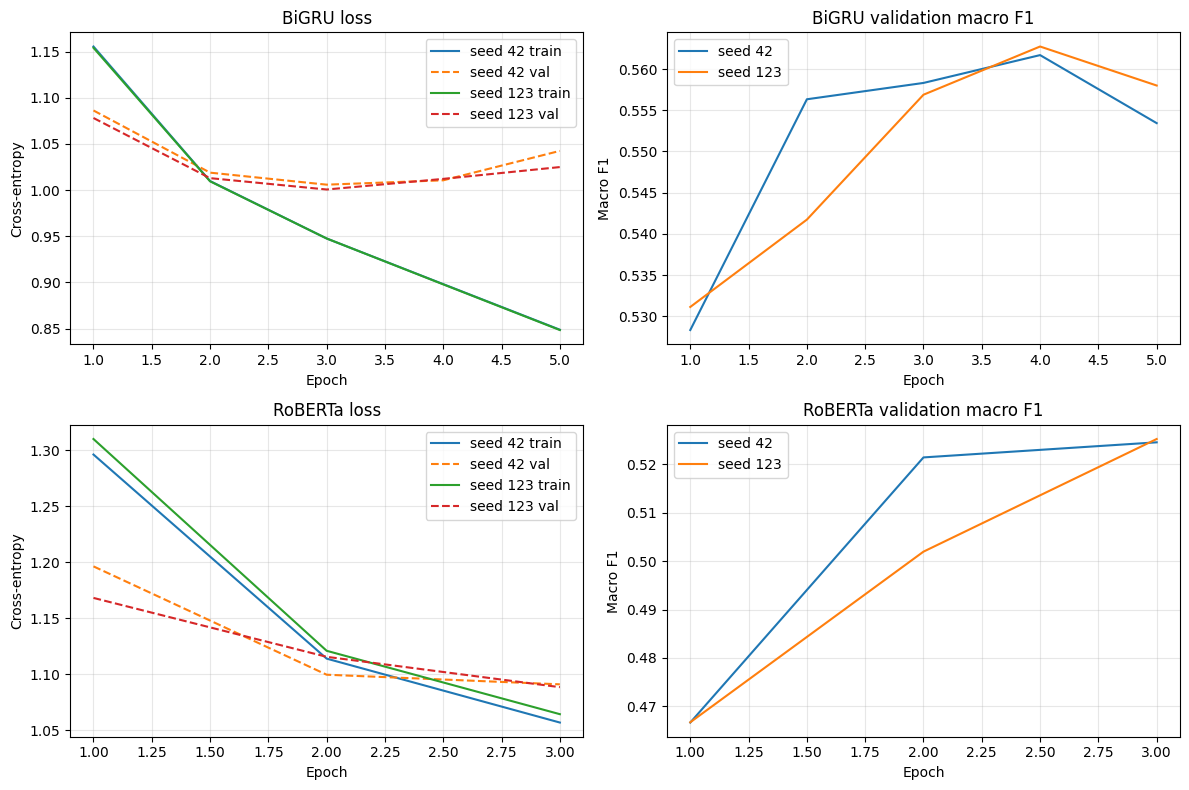

In [12]:
# Plot each seed separately to preserve actual epoch counts.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for seed in SEEDS:
    h = baseline_hist[seed]
    x = np.arange(1, len(h["train_loss"]) + 1)
    axes[0, 0].plot(x, h["train_loss"], label=f"seed {seed} train")
    axes[0, 0].plot(x, h["val_loss"], linestyle="--", label=f"seed {seed} val")
    axes[0, 1].plot(x, h["val_f1"], label=f"seed {seed}")
    h = roberta_hist[seed]
    x = np.arange(1, len(h["train_loss"]) + 1)
    axes[1, 0].plot(x, h["train_loss"], label=f"seed {seed} train")
    axes[1, 0].plot(x, h["val_loss"], linestyle="--", label=f"seed {seed} val")
    axes[1, 1].plot(x, h["val_f1"], label=f"seed {seed}")
for ax, title, ylabel in zip(
    axes.flat,
    [
        "BiGRU loss",
        "BiGRU validation macro F1",
        "RoBERTa loss",
        "RoBERTa validation macro F1",
    ],
    ["Cross-entropy", "Macro F1", "Cross-entropy", "Macro F1"],
):
    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Pooling ablation (validation only)

Masked mean pooling is compared with first-token pooling using seed 42. The ablation uses validation results, and masked mean pooling remains the primary model before test evaluation.


In [13]:
print("--- Validation pooling ablation: seed 42 ---")
roberta_cls_model, cls_history = train_roberta(seed=42, pooling="cls")
mean_val = evaluate(roberta_models[42], val_rob_loader, is_roberta=True)
cls_val = evaluate(roberta_cls_model, val_rob_loader, is_roberta=True)
ablation_df = pd.DataFrame(
    [
        {
            "Pooling": "Masked mean",
            "Accuracy": mean_val["acc"],
            "Macro F1": mean_val["macro_f1"],
            "MAE": mean_val["mae"],
        },
        {
            "Pooling": "First token (<s>)",
            "Accuracy": cls_val["acc"],
            "Macro F1": cls_val["macro_f1"],
            "MAE": cls_val["mae"],
        },
    ]
)
display(ablation_df)
print(
    "Interpret the validation differences here; do not use this table to tune against test results."
)

--- Validation pooling ablation: seed 42 ---


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [RoBERTa/cls seed 42 | Epoch 1] Batch 500/3125 - Loss: 1.4511
  [RoBERTa/cls seed 42 | Epoch 1] Batch 1000/3125 - Loss: 1.3490
  [RoBERTa/cls seed 42 | Epoch 1] Batch 1500/3125 - Loss: 1.2208
  [RoBERTa/cls seed 42 | Epoch 1] Batch 2000/3125 - Loss: 1.1086
  [RoBERTa/cls seed 42 | Epoch 1] Batch 2500/3125 - Loss: 1.1936
  [RoBERTa/cls seed 42 | Epoch 1] Batch 3000/3125 - Loss: 1.2284
  [RoBERTa/cls seed 42 | Epoch 1] Batch 3125/3125 - Loss: 1.0828
--> RoBERTa/cls seed=42 epoch=1: val macro-F1=0.4545, MAE=0.7348
  [RoBERTa/cls seed 42 | Epoch 2] Batch 500/3125 - Loss: 1.2267
  [RoBERTa/cls seed 42 | Epoch 2] Batch 1000/3125 - Loss: 1.2296
  [RoBERTa/cls seed 42 | Epoch 2] Batch 1500/3125 - Loss: 1.0899
  [RoBERTa/cls seed 42 | Epoch 2] Batch 2000/3125 - Loss: 1.3687
  [RoBERTa/cls seed 42 | Epoch 2] Batch 2500/3125 - Loss: 1.1048
  [RoBERTa/cls seed 42 | Epoch 2] Batch 3000/3125 - Loss: 1.1916
  [RoBERTa/cls seed 42 | Epoch 2] Batch 3125/3125 - Loss: 1.0446
--> RoBERTa/cls seed=42 epo

,Pooling,Accuracy,Macro F1,MAE
0,Masked mean,0.5316,0.524576,0.6082
1,First token (<s>),0.5302,0.521957,0.6102


Interpret the validation differences here; do not use this table to tune against test results.


### Ablation result

On validation, masked mean pooling reaches 0.5316 accuracy, 0.5246 macro F1, and 0.6082 MAE. First-token pooling reaches 0.5302, 0.5220, and 0.6102, respectively. The differences are small but consistently favor masked mean pooling, so it remains the primary RoBERTa setup. This is a validation result and was not used to select against the test set.


## 8. One final test evaluation

After model selection and ablation are complete, each final model is evaluated once on the held-out test split. These predictions are reused for metrics, confusion matrices, ordinal analysis, case studies, and saliency examples.


In [14]:
# Test loaders are created after training and validation ablation.
test_base_loader = DataLoader(
    TextDataset(test_texts, test_labels, vocab),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)
test_rob_loader = DataLoader(
    RobertaDataset(test_texts, test_labels, tokenizer),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_roberta,
    num_workers=NUM_WORKERS,
)
# One evaluation per trained model on the held-out test split.
bgru_tests = [
    evaluate(baseline_models[s], test_base_loader, is_roberta=False) for s in SEEDS
]
rob_tests = [
    evaluate(roberta_models[s], test_rob_loader, is_roberta=True) for s in SEEDS
]
def mean_std(vals, digits=4):
    if len(vals) <= 1:
        return f"{vals[0]:.{digits}f}"
    return f"{np.mean(vals):.{digits}f} ± {np.std(vals, ddof=1):.{digits}f}"
rows = []
for name, results in (
    ("BiGRU + additive attention", bgru_tests),
    ("RoBERTa + masked mean", rob_tests),
):
    row = {
        "Model": name,
        "Accuracy": mean_std([r["acc"] for r in results]),
        "Macro F1": mean_std([r["macro_f1"] for r in results]),
        "MAE (stars)": mean_std([r["mae"] for r in results]),
    }
    for i in range(5):
        row[f"F1 {i + 1}★"] = mean_std([r["per_class_f1"][i] for r in results])
    rows.append(row)
summary = pd.DataFrame(rows)
display(summary)


,Model,Accuracy,Macro F1,MAE (stars),F1 1★,F1 2★,F1 3★,F1 4★,F1 5★
0,BiGRU + additive attention,0.5684 ± 0.0000,0.5699 ± 0.0008,0.5191 ± 0.0038,0.6423 ± 0.0000,0.4733 ± 0.0081,0.4751 ± 0.0130,0.5222 ± 0.0167,0.7368 ± 0.0006
1,RoBERTa + masked mean,0.5380 ± 0.0037,0.5307 ± 0.0031,0.6123 ± 0.0021,0.6421 ± 0.0027,0.4344 ± 0.0178,0.4007 ± 0.0087,0.4749 ± 0.0186,0.7014 ± 0.0089


### Test-set comparison

Across the two seeds, the BiGRU reaches 56.84% ± 0.00% accuracy, 0.5699 ± 0.0008 macro F1, and 0.5191 ± 0.0038 MAE. RoBERTa reaches 53.80% ± 0.37%, 0.5307 ± 0.0031, and 0.6123 ± 0.0021. On these runs, the BiGRU is ahead by 3.04 percentage points in accuracy and 0.0392 in macro F1, with 0.0932 fewer stars of MAE. The expected advantage of the Transformer does not appear in this experiment; the short RoBERTa schedule is a plausible contributor, since validation macro F1 was still rising at epoch 3.

The confusion matrices and ordinal breakdown below use seed 42, while the summary table reports mean ± sample standard deviation across both seeds.


### Confusion matrices and ordinal errors

Confusion-matrix rows are normalized by true rating. Ordinal outcomes are grouped into exact predictions, one-star errors, and errors of two or more stars.


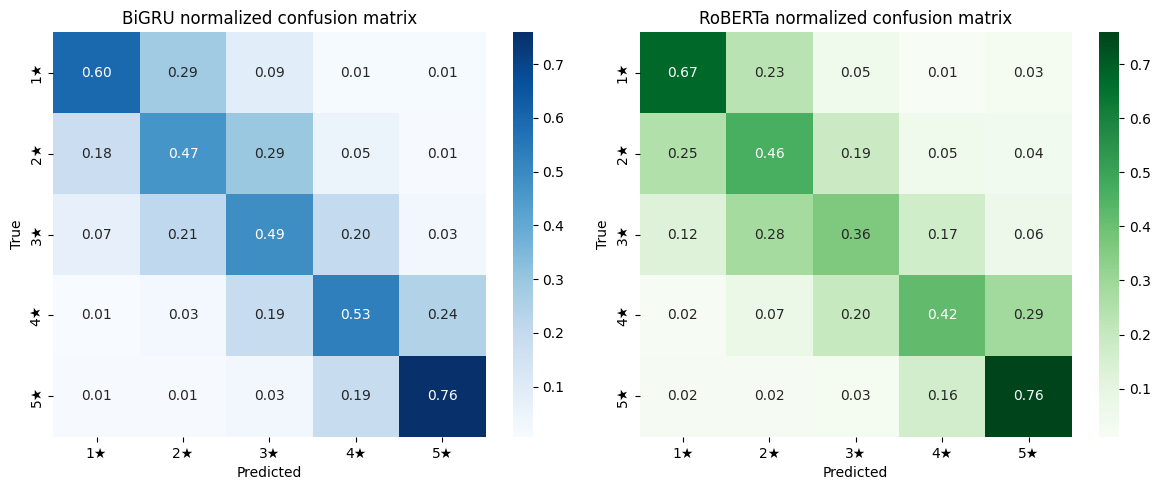

,Exact (Δ=0)%,Adjacent (Δ=1)%,Distant (Δ≥2)%
BiGRU,56.84,35.88,7.28
RoBERTa,53.54,35.52,10.94


In [15]:
# Reuse seed-42 predictions for confusion matrices and ordinal errors.
b_preds, b_true = bgru_tests[0]["preds"], bgru_tests[0]["targets"]
r_preds, r_true = rob_tests[0]["preds"], rob_tests[0]["targets"]
stars = ["1★", "2★", "3★", "4★", "5★"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(
    confusion_matrix(b_true, b_preds, labels=np.arange(5), normalize="true"),
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=stars,
    yticklabels=stars,
    ax=ax1,
)
ax1.set(title="BiGRU normalized confusion matrix", xlabel="Predicted", ylabel="True")
sns.heatmap(
    confusion_matrix(r_true, r_preds, labels=np.arange(5), normalize="true"),
    annot=True,
    fmt=".2f",
    cmap="Greens",
    xticklabels=stars,
    yticklabels=stars,
    ax=ax2,
)
ax2.set(title="RoBERTa normalized confusion matrix", xlabel="Predicted", ylabel="True")
plt.tight_layout()
plt.show()


def ordinal_breakdown(preds, targets):
    distance = np.abs(preds - targets)
    return [
        (distance == 0).mean() * 100,
        (distance == 1).mean() * 100,
        (distance >= 2).mean() * 100,
    ]


ordinal_df = pd.DataFrame(
    [ordinal_breakdown(b_preds, b_true), ordinal_breakdown(r_preds, r_true)],
    index=["BiGRU", "RoBERTa"],
    columns=["Exact (Δ=0)%", "Adjacent (Δ=1)%", "Distant (Δ≥2)%"],
)
display(ordinal_df)

### Confusion and ordinal interpretation

Both systems make mostly adjacent-rating errors. For seed 42, exact/adjacent/distant errors are 56.84%/35.88%/7.28% for the BiGRU and 53.54%/35.52%/10.94% for RoBERTa. The BiGRU has lower distant error in this run. In the normalized matrices, RoBERTa recalls more one-star reviews (0.67 vs. 0.60), but the BiGRU has higher diagonal recall for ratings 2–4; both reach 0.76 for five-star reviews. A common pattern is confusion between neighboring ratings, especially 1↔2 and 4↔5.


### Review case studies

Review text is examined alongside both predictions and the true rating. The examples support discussion of visible linguistic patterns rather than treating model outputs as self-explanatory.


In [16]:
# Select case studies from the stored test predictions.
case_base_wins, case_roberta_wins = [], []
for i, (t, b, r) in enumerate(zip(b_true, b_preds, r_preds)):
    record = {
        "index": i,
        "text": test_texts[i],
        "true_star": int(t) + 1,
        "BiGRU_star": int(b) + 1,
        "RoBERTa_star": int(r) + 1,
    }
    if r == t and b != t and len(case_roberta_wins) < 5:
        case_roberta_wins.append(record)
    if b == t and r != t and len(case_base_wins) < 2:
        case_base_wins.append(record)
print("BiGRU wrong, RoBERTa correct:")
for ex in case_roberta_wins:
    print(ex)
print("\nRoBERTa wrong, BiGRU correct (report fewer than two if fewer exist):")
for ex in case_base_wins:
    print(ex)
print(
    f"Found {len(case_roberta_wins)}/5 RoBERTa wins and {len(case_base_wins)}/2 baseline wins."
)

BiGRU wrong, RoBERTa correct:
{'index': 5, 'text': 'I was over the moon when I got this. I love sunflowers and it looked exactly like they advertised, unfortunately I wore this piercing for one weekend. By Sunday night the sunflower had came off. I will not be purchasing from this company again. Very disappointed.', 'true_star': 1, 'BiGRU_star': 2, 'RoBERTa_star': 1}
{'index': 13, 'text': 'My package arrived with nothing in it?! My cord that I use for my phone is broken and I was really depending on this replacement. I will give a better rating when I have something to rate!!', 'true_star': 1, 'BiGRU_star': 2, 'RoBERTa_star': 1}
{'index': 17, 'text': 'Belt loops were not fastened upon opening. They were not stitched.', 'true_star': 1, 'BiGRU_star': 2, 'RoBERTa_star': 1}
{'index': 20, 'text': "Had them for like a month, during which time I used them maybe once for 5 minutes. Otherwise kept in the included case. They broke right away. The nosepiece - which is made of a paper-like materia

### What the case studies suggest

All five RoBERTa-only correct cases are true one-star reviews that the BiGRU predicts as two stars. They include mixed sentiment followed by a product failure (the sunflower piercing), an empty package and broken replacement cord, unstitched belt loops, glasses that break after minimal use, and a battery cover that strips on the first day. These examples suggest that RoBERTa sometimes handles a positive opening followed by a decisive negative outcome, or integrates multiple concrete defect details. The baseline-only correct examples are also one-star cases: one mixes severe fabric/fit criticism with a compliment about customer service, and the other is the short complaint “Ran entirely too small.” The errors are all one-star shifts, not distant mistakes. These are illustrative examples, not enough evidence to establish a general linguistic advantage.


### Token-level interpretation

The visualization shows the baseline’s learned attention weights and RoBERTa’s input-embedding gradient saliency for its predicted class. Saliency is interpreted as a measure of model sensitivity, not as a causal explanation.


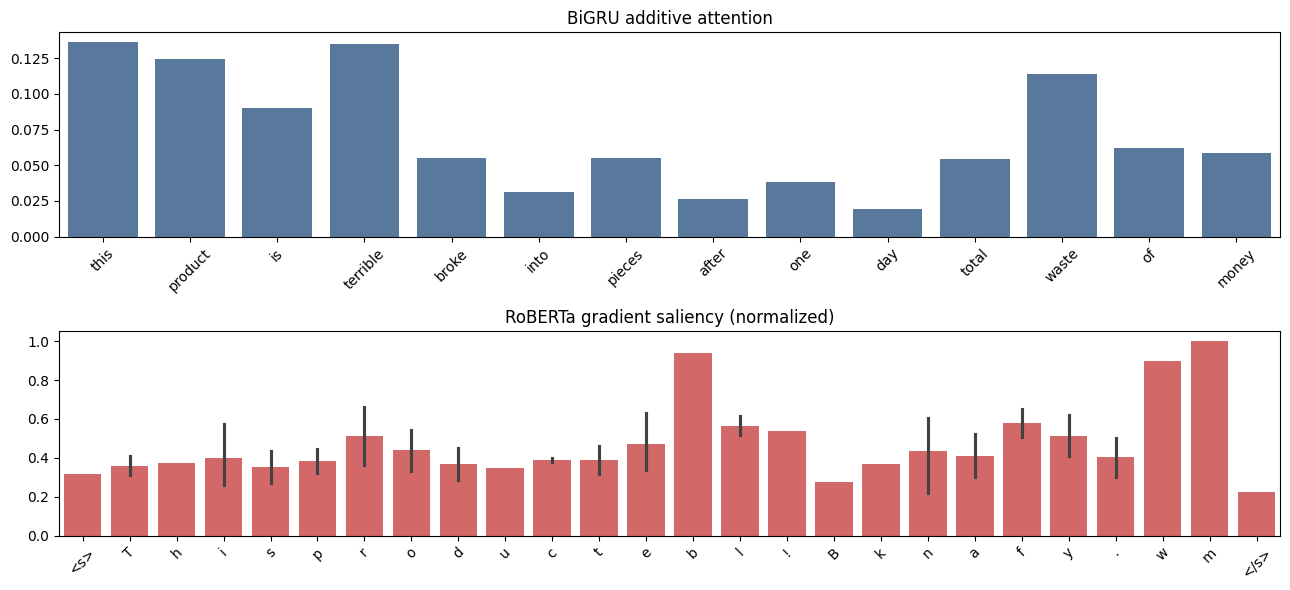

In [17]:
# Baseline attention and RoBERTa input-embedding saliency for one example.
sample_review = (
    "This product is terrible! Broke into pieces after one day. Total waste of money."
)

bgru = baseline_models[42].eval()
tokens = tokenize(sample_review)[:BASE_MAX_LEN] or ["<unk>"]
ids_list = [vocab.get(t, vocab["<unk>"]) for t in tokens]
ids = torch.tensor([ids_list + [0] * (BASE_MAX_LEN - len(ids_list))], device=DEVICE)
with torch.no_grad():
    _, attn = bgru(ids)
attn_weights = attn[0, : len(tokens)].cpu().numpy()

rob = roberta_models[42].eval()
enc = tokenizer(
    sample_review, truncation=True, max_length=ROBERTA_MAX_LEN, return_tensors="pt"
).to(DEVICE)
emb = (
    rob.roberta.embeddings.word_embeddings(enc["input_ids"])
    .detach()
    .requires_grad_(True)
)
rob.zero_grad(set_to_none=True)
logits = rob(inputs_embeds=emb, attention_mask=enc["attention_mask"])
logits[0, logits.argmax(dim=-1)].backward()
saliency = emb.grad[0].norm(dim=-1).detach().cpu().numpy()
subwords = tokenizer.convert_ids_to_tokens(enc["input_ids"][0].detach().cpu())
fig, axes = plt.subplots(2, 1, figsize=(13, 6))
sns.barplot(x=tokens, y=attn_weights, ax=axes[0], color="#4c78a8")
axes[0].set_title("BiGRU additive attention")
axes[0].tick_params(axis="x", rotation=45)
sns.barplot(
    x=subwords, y=saliency / (saliency.max() + 1e-12), ax=axes[1], color="#e45756"
)
axes[1].set_title("RoBERTa gradient saliency (normalized)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### Interpretability reading

For the sample review, the BiGRU assigns relatively high attention weights to “this,” “product,” “terrible,” and “waste.” RoBERTa's gradient-saliency plot varies across subword positions, with prominent responses around parts of the negative product-failure description. The subword labels are crowded in the saved figure, so token-level conclusions should be treated cautiously. Neither visualization proves that a highlighted token caused the prediction.


## 9. Discussion and limitations

The full prescribed split sizes were used: 200,000 training, 5,000 validation, and 5,000 test reviews. The held-out test split was evaluated after checkpoint selection and the validation-only pooling ablation. Its predictions were reused for the displayed matrices, ordinal analysis, and case studies.

The BiGRU is the stronger model in these saved test results, despite RoBERTa's pretrained contextual representation. RoBERTa's validation macro F1 rises from 0.4666 to 0.5246 for seed 42 and from 0.4667 to 0.5253 for seed 123 over its three epochs. Since both runs are still improving at the final epoch, these results do not establish that RoBERTa had converged. More epochs could change the comparison, but the reported test set should not be reused to tune the extension.

The recurrent baseline uses fixed-length padded inputs without packed sequences. Although attention masks exclude padding positions from pooling, the backward GRU still processes padding; this may influence hidden states and is a methodological limitation of the evaluated checkpoint. The confusion matrices and ordinal breakdown are shown for seed 42 only, whereas the summary metrics use both seeds. The two-seed estimates also provide limited information about variability.

A concise report using the measured results and case analysis is provided in `report.md`. The report avoids claiming that the present RoBERTa run is fully converged.
